In [1]:
import time
import gymnasium as gym
from gymnasium.wrappers import RecordVideo
from IPython.display import clear_output, display
from PIL import Image

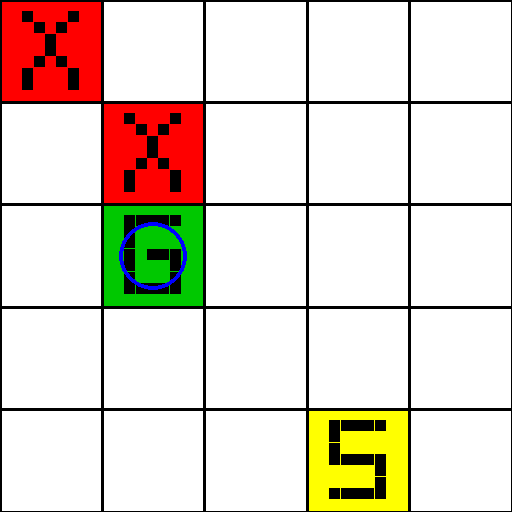

In [2]:
from grid_maze_env import GridMazeEnv

SEED = 0

env = GridMazeEnv(render_mode="rgb_array", size=5)

observation, info = env.reset(seed=SEED)

for _ in range(40):
    action = env.action_space.sample()
    observation, reward, terminated, truncated, info = env.step(action)

    clear_output(wait=True)
    display(Image.fromarray(env.render()))

    if terminated or truncated:
        break

env.close()

In [3]:
from policy_iteration import PolicyIteration

policy_iteration = PolicyIteration(env)
policy, value_function = policy_iteration.run_policy_iteration()

print("Number of iterations:", policy_iteration.num_iterations)
PolicyIteration.print_results(policy, value_function, env.size)

Number of iterations: 6
Policy and value function
Legend: → RIGHT, ↑ UP, ← LEFT, ↓ DOWN
+-----------+-----------+-----------+-----------+-----------+
|   ↓ 0.980 |   → 0.970 |   ↓ 0.980 |   ← 0.970 |   ← 0.961 |
+-----------+-----------+-----------+-----------+-----------+
|   ↓ 0.990 |   ↓ 1.000 |   ↓ 0.990 |   ← 0.980 |   ← 0.970 |
+-----------+-----------+-----------+-----------+-----------+
|   → 1.000 |   → 0.000 |   ← 1.000 |   ← 0.990 |   ← 0.980 |
+-----------+-----------+-----------+-----------+-----------+
|   → 0.990 |   ↑ 1.000 |   ↑ 0.990 |   ↑ 0.980 |   ↑ 0.970 |
+-----------+-----------+-----------+-----------+-----------+
|   → 0.980 |   ↑ 0.990 |   ↑ 0.980 |   ↑ 0.970 |   ↑ 0.961 |
+-----------+-----------+-----------+-----------+-----------+


/Users/morsy/Documents/Uni Projects/Reinforcement Learning/Assignment-2/.venv/lib/python3.14/site-packages/gymnasium/wrappers/rendering.py:298: UserWarning: WARN: Overwriting existing videos at /Users/morsy/Documents/Uni Projects/Reinforcement Learning/Assignment-2/videos folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


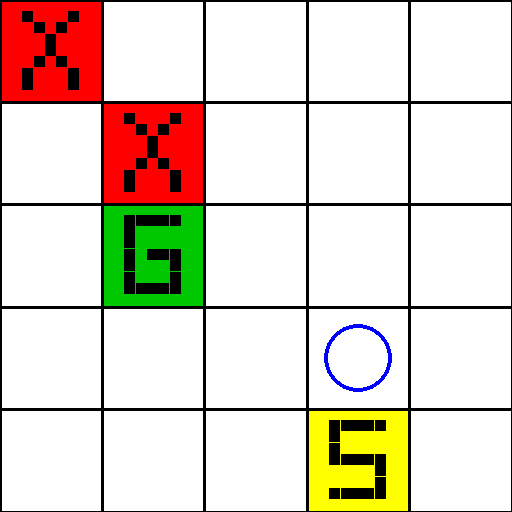

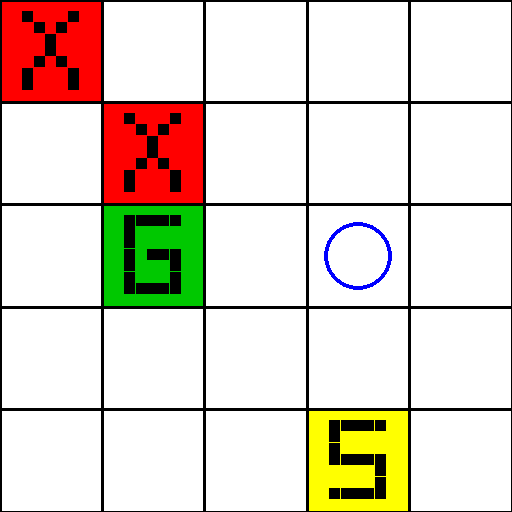

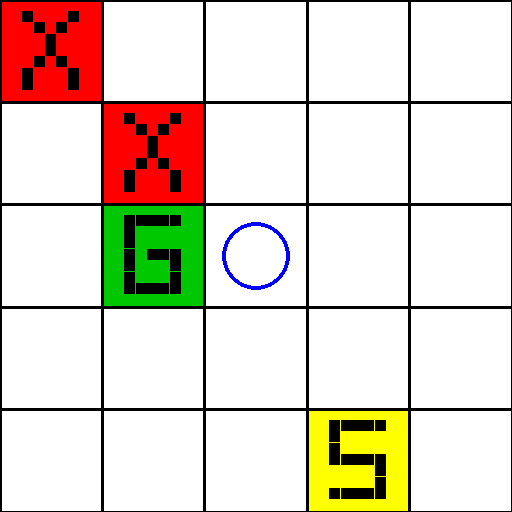

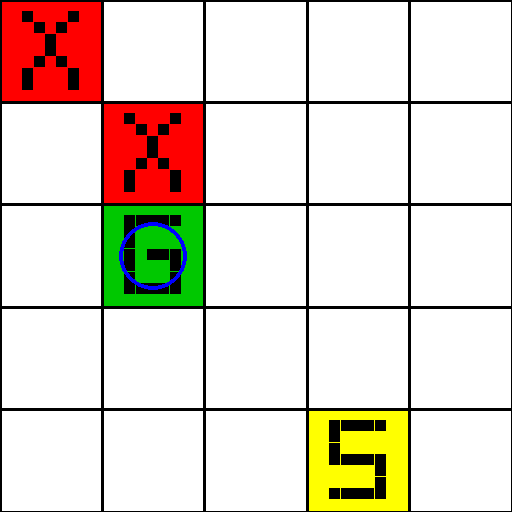

Video saved to the 'videos' directory.


In [4]:
from gymnasium.wrappers import RecordVideo

# Wrap the environment with RecordVideo to record the agent running the optimal policy
record_env = gym.wrappers.RecordVideo(
    GridMazeEnv(render_mode="rgb_array", size=env.size),
    video_folder="videos",
    episode_trigger=lambda episode_id: True,
)

# Run the calculated optimal policy
observation, info = record_env.reset(seed=SEED)

while True:
    state = env.state_from_location(observation["agent"])
    action = int(policy[state])
    observation, reward, terminated, truncated, info = record_env.step(action)

    display(Image.fromarray(record_env.render()))

    if terminated or truncated:
        break

record_env.close()
print("Video saved to the 'videos' directory.")
